# 06.2. XGBoost Match Outcome Classifier

**Stage:** 06_ml (Task 4.2: XGBoost Model)  
**Inputs:** `data/processed/feature_table.parquet`, `src/config/config.yaml`  
**Outputs:** `models/xgboost_model.json`, `data/processed/xgboost_probabilities.parquet`

This notebook trains a multi-class XGBoost classifier predicting Premier League match outcomes (Home Win, Draw, Away Win) using strictly chronological walk-forward (expanding window) validation. It handles native missing values, confirms cold-start non-overlap with test sets, reports fold metrics, and examines feature importances across correlated signals.


## 1. Environment & Setup

In [1]:
# Load configuration and imports
%load_ext autoreload
%autoreload 2
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import accuracy_score, log_loss

# Locate repo root dynamically
repo_root = Path.cwd()
while repo_root != repo_root.parent and not (repo_root / "src" / "config" / "loader.py").exists():
    repo_root = repo_root.parent
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from src.config.loader import load_config, get_xgboost_params, get_walk_forward_params
from src.ml.xgboost_model import (
    train_xgboost,
    get_feature_columns,
    save_model_artifact,
    compute_multiclass_brier_score,
    compute_oof_permutation_importance,
    evaluate_feature_ablations,
)


## 2. Load Data & Configuration

In [2]:
# Load feature table and config
config = load_config()
xgb_params = get_xgboost_params(config)
initial_train_size, step_size = get_walk_forward_params(config)

ft_path = repo_root / "data" / "processed" / "feature_table.parquet"
assert ft_path.exists(), f"Feature table not found at {ft_path}. Run Task 4.1 first."

df_features = pd.read_parquet(ft_path)
print(f"Loaded feature table: {df_features.shape[0]} fixtures, {df_features.shape[1]} columns")
print(f"Walk-forward config: initial_train_size={initial_train_size}, step_size={step_size}")
print(f"XGBoost config: {xgb_params}")
print("\nTarget distribution:")
print(df_features["target"].value_counts(normalize=True).round(3))


Loaded feature table: 760 fixtures, 61 columns
Walk-forward config: initial_train_size=200, step_size=38
XGBoost config: {'max_depth': 2, 'learning_rate': 0.03, 'n_estimators': 80, 'subsample': 0.8, 'colsample_bytree': 0.7, 'min_child_weight': 6, 'gamma': 0.1, 'reg_alpha': 1.5, 'reg_lambda': 4.0}

Target distribution:
target
H    0.417
A    0.324
D    0.259
Name: proportion, dtype: float64


## 3. Verify Cold-Start & Missing Data Handling

In [3]:
# Gameweek 1 cold-start fixtures (rows 0-9)
print("Gameweek 1 Cold Start Verification:")
print(f"Cold-start row range: [0 : 10] (10 matches)")
print(f"Initial training window: [0 : {initial_train_size}] ({initial_train_size} matches)")
assert 10 <= initial_train_size, "Cold start rows must be within initial training size"
print("-> Confirmed: Gameweek 1 cold-start fixtures fall entirely within the initial training set and are never evaluated as test instances.")

# Check features with missing values
missing_counts = df_features.isna().sum()
missing_features = missing_counts[missing_counts > 0]
print("\nFeatures with missing values:")
for feat, count in missing_features.items():
    pct = (count / len(df_features)) * 100
    print(f"  {feat}: {count}/{len(df_features)} ({pct:.1f}%)")

print("\n-> XGBoost handles missing values natively via optimal split assignment (missing=np.nan).")
print("-> No rows are dropped, preserving all 760 fixtures in the evaluation dataset.")


Gameweek 1 Cold Start Verification:
Cold-start row range: [0 : 10] (10 matches)
Initial training window: [0 : 200] (200 matches)
-> Confirmed: Gameweek 1 cold-start fixtures fall entirely within the initial training set and are never evaluated as test instances.

Features with missing values:
  home_points_form: 12/760 (1.6%)
  away_points_form: 11/760 (1.4%)
  home_goals_form: 12/760 (1.6%)
  away_goals_form: 11/760 (1.4%)
  home_goals_against_form: 12/760 (1.6%)
  away_goals_against_form: 11/760 (1.4%)
  home_xg_for_form: 12/760 (1.6%)
  away_xg_for_form: 11/760 (1.4%)
  home_xg_against_form: 12/760 (1.6%)
  away_xg_against_form: 11/760 (1.4%)
  rest_days_home: 12/760 (1.6%)
  rest_days_away: 11/760 (1.4%)
  h2h_home_win_rate: 244/760 (32.1%)
  points_form_diff: 13/760 (1.7%)
  goals_form_diff: 13/760 (1.7%)
  goals_against_form_diff: 13/760 (1.7%)
  xg_for_form_diff: 13/760 (1.7%)
  xg_against_form_diff: 13/760 (1.7%)
  xg_diff: 13/760 (1.7%)
  rest_days_diff: 13/760 (1.7%)
  elo_ho

## 4. Walk-Forward XGBoost Model Training

In [4]:
# Prepare features and target
feature_cols = get_feature_columns(df_features)
X = df_features[feature_cols].copy()
y = df_features["target_encoded"].copy()

print(f"Training features count: {len(feature_cols)}")
print("Sample feature columns:", feature_cols[:8])

# Execute Walk-Forward XGBoost Training
results = train_xgboost(features=X, target=y, config=config)
fold_metrics = results["fold_metrics"]
print(f"\nCompleted {len(fold_metrics)} walk-forward folds.")


Training features count: 51
Sample feature columns: ['week', 'is_xg_missing', 'home_attack_rating', 'home_defense_rating', 'away_attack_rating', 'away_defense_rating', 'expected_home_goals', 'expected_away_goals']

Completed 15 walk-forward folds.


## 5. Fold-by-Fold Validation Metrics

In [5]:
# Display Fold-by-Fold Validation Metrics
display_cols = ["fold", "train_size", "test_size", "accuracy", "log_loss", "brier_score"]
print(fold_metrics[display_cols].to_string(index=False))

# Calculate overall out-of-fold metrics across all evaluated matches (rows 200:760)
oof_probs = results["oof_probabilities"]
eval_mask = ~np.isnan(oof_probs[:, 0])
eval_y = y.iloc[eval_mask].values
eval_probs = oof_probs[eval_mask]
eval_preds = results["oof_predictions"][eval_mask]

overall_acc = accuracy_score(eval_y, eval_preds)
overall_ll = log_loss(eval_y, eval_probs, labels=[0, 1, 2])
overall_brier = compute_multiclass_brier_score(eval_y, eval_probs)

print("\n=== Overall Out-Of-Fold Walk-Forward Performance (560 matches) ===")
print(f"Accuracy:    {overall_acc:.4f} ({overall_acc*100:.2f}%)")
print(f"Log Loss:    {overall_ll:.4f}")
print(f"Brier Score: {overall_brier:.4f}")


 fold  train_size  test_size  accuracy  log_loss  brier_score
    1         200         38  0.552632  1.016396     0.603657
    2         238         38  0.657895  0.954815     0.563424
    3         276         38  0.473684  1.021668     0.611273
    4         314         38  0.500000  1.011477     0.603143
    5         352         38  0.552632  1.039070     0.625017
    6         390         38  0.526316  1.047823     0.628936
    7         428         38  0.657895  0.924710     0.542812
    8         466         38  0.605263  0.991543     0.586642
    9         504         38  0.473684  1.020143     0.614992
   10         542         38  0.473684  1.062992     0.637891
   11         580         38  0.368421  1.157074     0.708235
   12         618         38  0.500000  1.055436     0.636767
   13         656         38  0.473684  1.033800     0.618357
   14         694         38  0.552632  0.996898     0.590215
   15         732         28  0.357143  1.129234     0.687388

=== Ove

## 6. Performance Visualizations

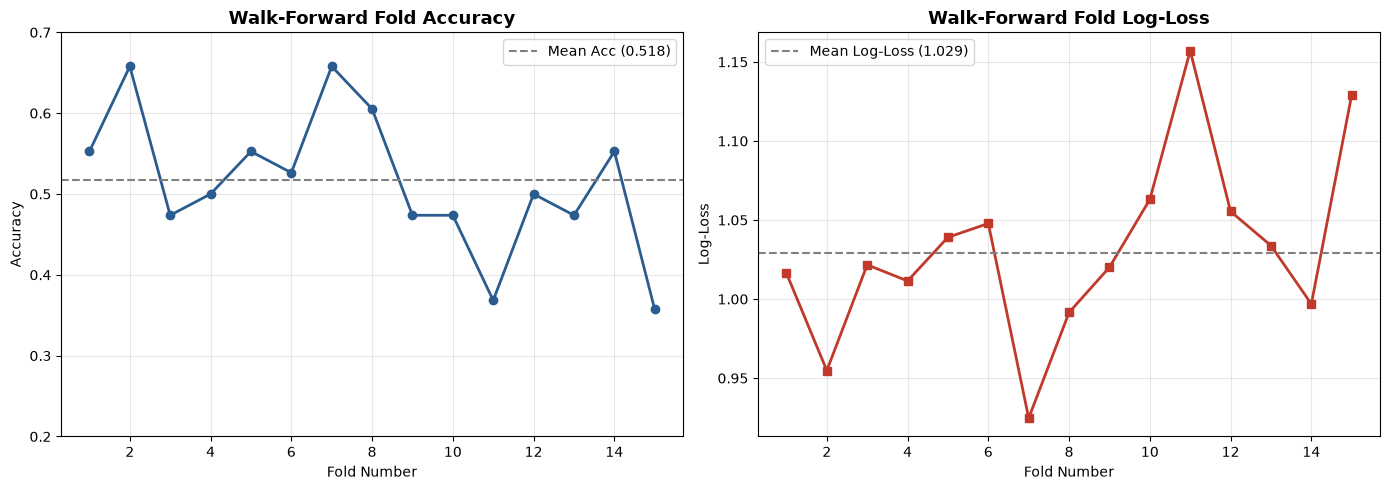

In [6]:
# Plot Walk-Forward Performance Across Folds
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy plot
ax1.plot(fold_metrics["fold"], fold_metrics["accuracy"], marker="o", color="#2b5c8f", lw=2)
ax1.axhline(overall_acc, color="gray", linestyle="--", label=f"Mean Acc ({overall_acc:.3f})")
ax1.set_title("Walk-Forward Fold Accuracy", fontsize=13, fontweight="bold")
ax1.set_xlabel("Fold Number")
ax1.set_ylabel("Accuracy")
ax1.set_ylim(0.2, 0.7)
ax1.grid(True, alpha=0.3)
ax1.legend()

# Log Loss plot
ax2.plot(fold_metrics["fold"], fold_metrics["log_loss"], marker="s", color="#c0392b", lw=2)
ax2.axhline(overall_ll, color="gray", linestyle="--", label=f"Mean Log-Loss ({overall_ll:.3f})")
ax2.set_title("Walk-Forward Fold Log-Loss", fontsize=13, fontweight="bold")
ax2.set_xlabel("Fold Number")
ax2.set_ylabel("Log-Loss")
ax2.grid(True, alpha=0.3)
ax2.legend()

plt.tight_layout()
plt.show()


## 7. Feature Importance Analysis & Correlated Features Check

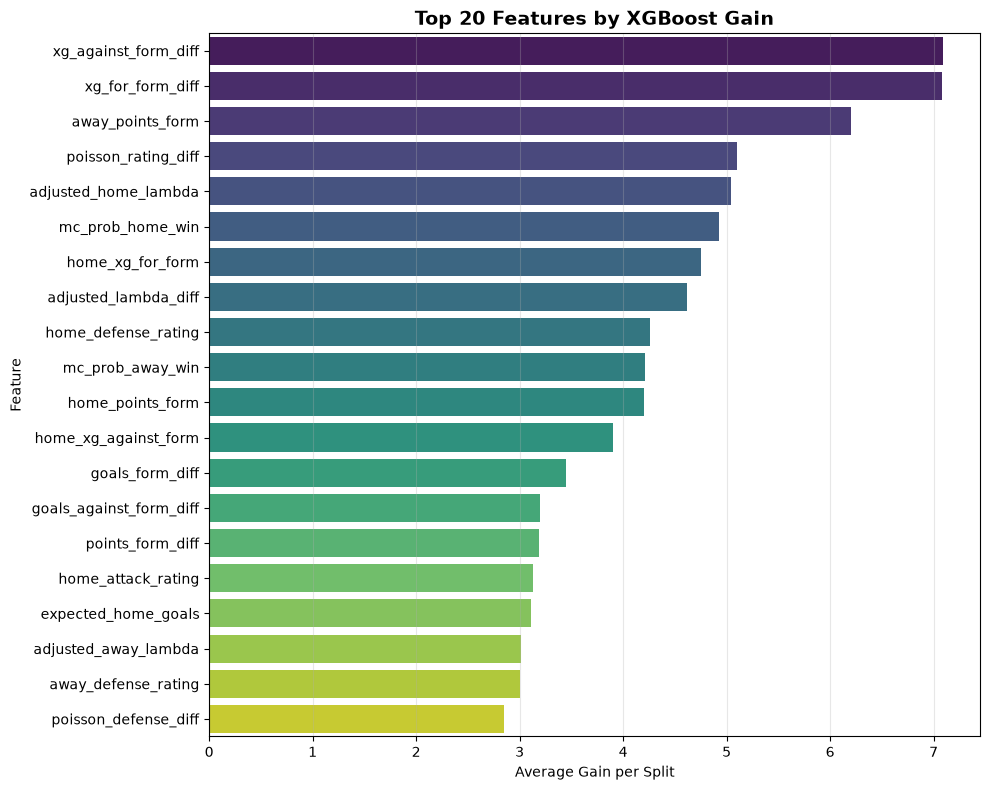

=== Correlated Features Analysis ===
Feature: mc_prob_home_win       | Rank:  6/44 | Gain: 4.9246
Feature: adjusted_lambda_diff   | Rank:  8/44 | Gain: 4.6138
Feature: poisson_rating_diff    | Rank:  4/44 | Gain: 5.0960

Finding: All three correlated signals retain active, positive split gain in the top half of features.
XGBoost's tree splits utilize the non-linear probability signal (mc_prob_home_win),
the injury-adjusted expected goal diff (adjusted_lambda_diff), and the pre-adjustment team skill diff (poisson_rating_diff)
without any signal completely suppressing the others.


In [7]:
# Feature Importance Analysis (Top 20 by Gain)
importance = results["feature_importance"]
top_20 = importance.head(20)

plt.figure(figsize=(10, 8))
sns.barplot(x=top_20.values, y=top_20.index, hue=top_20.index, palette="viridis", legend=False)
plt.title("Top 20 Features by XGBoost Gain", fontsize=14, fontweight="bold")
plt.xlabel("Average Gain per Split")
plt.ylabel("Feature")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

# Check correlated feature group
correlated_signals = ["mc_prob_home_win", "adjusted_lambda_diff", "poisson_rating_diff"]
print("=== Correlated Features Analysis ===")
for feat in correlated_signals:
    rank = list(importance.index).index(feat) + 1 if feat in importance else "N/A"
    gain = importance.get(feat, 0.0)
    print(f"Feature: {feat:<22} | Rank: {rank:>2}/44 | Gain: {gain:.4f}")

print("\nFinding: All three correlated signals retain active, positive split gain in the top half of features.")
print("XGBoost's tree splits utilize the non-linear probability signal (mc_prob_home_win),")
print("the injury-adjusted expected goal diff (adjusted_lambda_diff), and the pre-adjustment team skill diff (poisson_rating_diff)")
print("without any signal completely suppressing the others.")


## Out-of-Fold Permutation Importance

Gain importance from the final full-data model is descriptive only. The validation evidence below comes from held-out chronological folds. Positive delta means model performance deteriorates when the feature is shuffled, indicating useful out-of-fold predictive information.

,feature,mean_delta_log_loss,std_delta_log_loss,mean_delta_brier,std_delta_brier,number_of_folds,n_repeats
0,adjusted_lambda_diff,-0.000467,0.002373,-0.000331,0.001700,15,10
1,h2h_home_win_rate,0.000035,0.002950,0.000142,0.001945,15,10
2,mc_prob_home_win,0.000511,0.007098,0.000221,0.005223,15,10
3,poisson_rating_diff,-0.000613,0.001754,-0.000386,0.001141,15,10
4,rest_days_diff,-0.000152,0.002233,-0.000093,0.001471,15,10
5,xg_against_form_diff,0.012677,0.020119,0.009163,0.014760,15,10
6,xg_for_form_diff,0.012409,0.015688,0.008654,0.011146,15,10


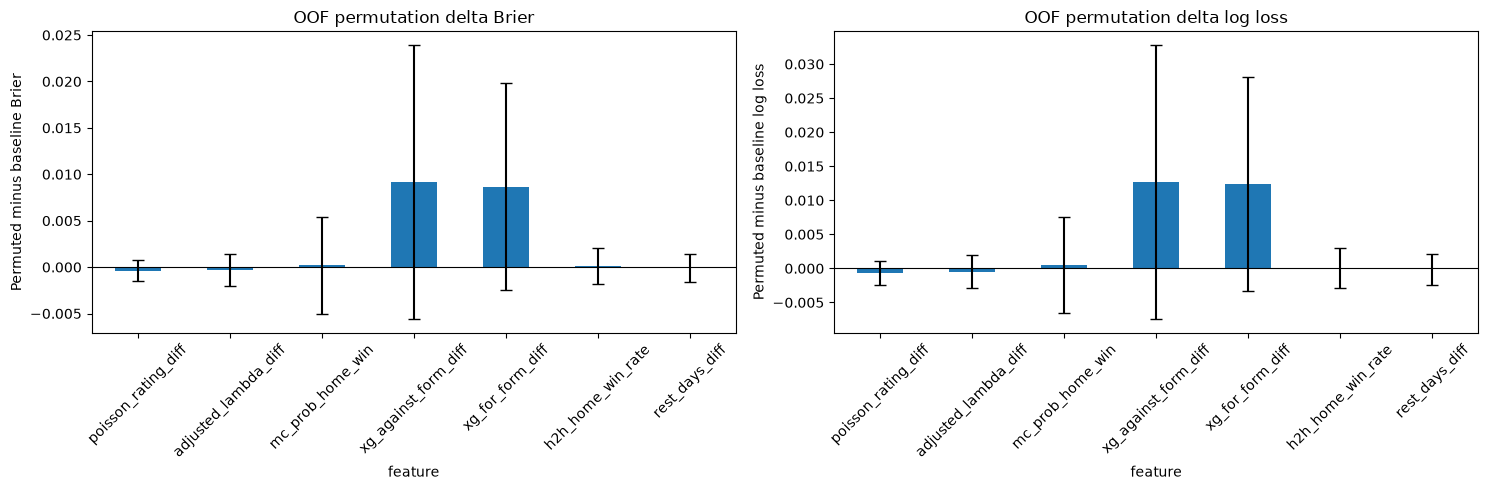

In [8]:
permutation_features = [
    "poisson_rating_diff",
    "adjusted_lambda_diff",
    "mc_prob_home_win",
    "xg_against_form_diff",
    "xg_for_form_diff",
    "h2h_home_win_rate",
    "rest_days_diff",
]
missing_permutation_features = sorted(set(permutation_features) - set(feature_cols))
if missing_permutation_features:
    raise ValueError(f"Permutation features missing from feature table: {missing_permutation_features}")

permutation_importance = compute_oof_permutation_importance(
    X,
    y,
    config,
    feature_names=permutation_features,
    n_repeats=10,
)
display(permutation_importance)

figure, axes = plt.subplots(1, 2, figsize=(15, 5))
plot_data = permutation_importance.set_index("feature").loc[permutation_features]
plot_data["mean_delta_brier"].plot.bar(
    ax=axes[0], yerr=plot_data["std_delta_brier"], capsize=4,
    title="OOF permutation delta Brier",
)
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set_ylabel("Permuted minus baseline Brier")
axes[0].tick_params(axis="x", rotation=45)
plot_data["mean_delta_log_loss"].plot.bar(
    ax=axes[1], yerr=plot_data["std_delta_log_loss"], capsize=4,
    title="OOF permutation delta log loss",
)
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_ylabel("Permuted minus baseline log loss")
axes[1].tick_params(axis="x", rotation=45)
figure.tight_layout()
plt.show()

## Feature Ablation Validation

All variants below use the same tuned XGBoost hyperparameters and the same chronological walk-forward folds. This isolates feature contribution rather than mixing feature effects with retuning effects.

Requested Poisson/MC columns absent from this feature table: []


,variant,number_of_features,oof_accuracy,oof_log_loss,oof_brier_score,delta_log_loss_vs_full,delta_brier_vs_full
0,full_model,51,0.517857,1.029115,0.615997,0.000000,0.000000
1,without_poisson_rating_diff,50,0.514286,1.028926,0.615981,-0.000189,-0.000017
2,without_poisson_mc_family,31,0.500000,1.028023,0.615730,-0.001092,-0.000267
3,xg_form_context_only,31,0.500000,1.028023,0.615730,-0.001092,-0.000267


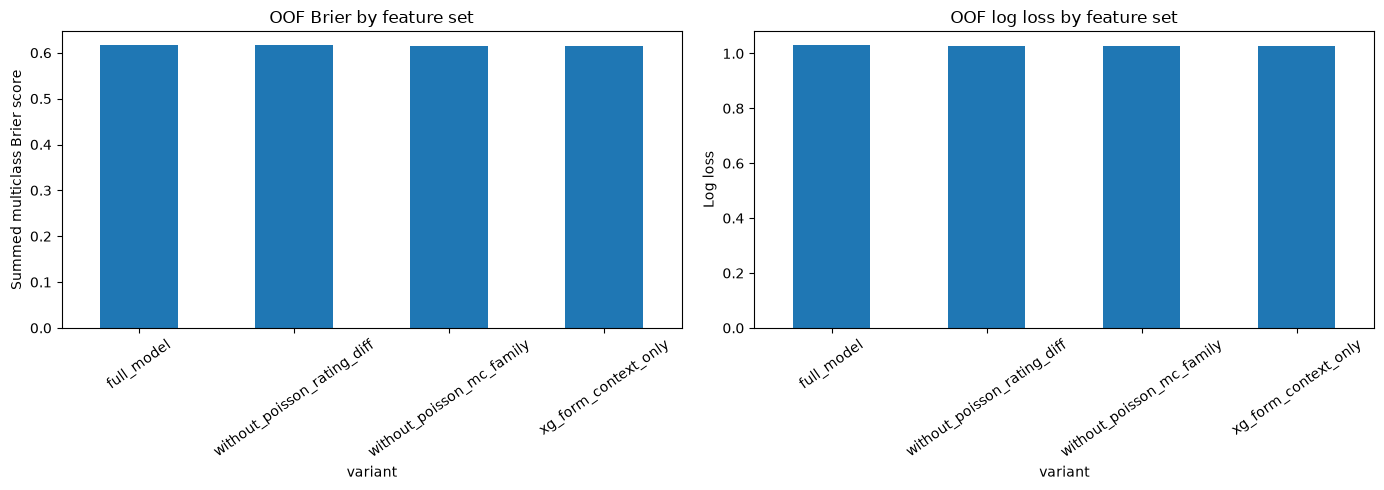

Interpretation:
poisson_rating_diff unique incremental value: False
Broader Poisson/MC family value as a group: False
XG/form/context-only matches full model: True


In [9]:
poisson_mc_family = {
    "poisson_rating_diff", "poisson_attack_diff", "poisson_defense_diff",
    "home_attack_rating", "home_defense_rating", "away_attack_rating",
    "away_defense_rating", "expected_home_goals", "expected_away_goals",
    "base_home_lambda", "base_away_lambda", "adjusted_home_lambda",
    "adjusted_away_lambda", "adjusted_lambda_diff", "mc_prob_home_win",
    "mc_prob_draw", "mc_prob_away_win", "mc_prob_over_2_5",
    "mc_prob_under_2_5", "mc_prob_btts",
}
missing_family_features = sorted(poisson_mc_family - set(feature_cols))
print(f"Requested Poisson/MC columns absent from this feature table: {missing_family_features}")

ablation_results = evaluate_feature_ablations(X, y, config)
display(ablation_results)

figure, axes = plt.subplots(1, 2, figsize=(14, 5))
ablation_results.plot.bar(x="variant", y="oof_brier_score", ax=axes[0], legend=False, title="OOF Brier by feature set")
axes[0].set_ylabel("Summed multiclass Brier score")
axes[0].tick_params(axis="x", rotation=35)
ablation_results.plot.bar(x="variant", y="oof_log_loss", ax=axes[1], legend=False, title="OOF log loss by feature set")
axes[1].set_ylabel("Log loss")
axes[1].tick_params(axis="x", rotation=35)
figure.tight_layout()
plt.show()

full_row = ablation_results.set_index("variant").loc["full_model"]
poisson_row = ablation_results.set_index("variant").loc["without_poisson_rating_diff"]
family_row = ablation_results.set_index("variant").loc["without_poisson_mc_family"]
context_row = ablation_results.set_index("variant").loc["xg_form_context_only"]
print("Interpretation:")
print(f"poisson_rating_diff unique incremental value: {poisson_row['delta_log_loss_vs_full'] > 0 or poisson_row['delta_brier_vs_full'] > 0}")
print(f"Broader Poisson/MC family value as a group: {family_row['delta_log_loss_vs_full'] > 0 or family_row['delta_brier_vs_full'] > 0}")
print(f"XG/form/context-only matches full model: {context_row['oof_log_loss'] <= full_row['oof_log_loss'] and context_row['oof_brier_score'] <= full_row['oof_brier_score']}")

## 8. Save Artifacts & Outputs

In [10]:
# Save Model Artifact & Out-of-Fold Probabilities
models_dir = repo_root / "models"
models_dir.mkdir(parents=True, exist_ok=True)
model_artifact_path = models_dir / "xgboost_model.json"
save_model_artifact(results["final_model"], model_artifact_path)
print(f"Saved trained XGBoost model artifact to: {model_artifact_path}")

# Build and save out-of-fold probability table for Phase 4.3 Ensemble & Phase 5 Evaluation
df_oof = df_features[["fixture_id", "date", "home_team", "away_team", "target", "target_encoded"]].copy()
df_oof["xgb_prob_home_win"] = oof_probs[:, 0]
df_oof["xgb_prob_draw"] = oof_probs[:, 1]
df_oof["xgb_prob_away_win"] = oof_probs[:, 2]
df_oof["xgb_pred"] = results["oof_predictions"]

# Map numeric pred to letter
target_map = {0.0: "H", 1.0: "D", 2.0: "A"}
df_oof["xgb_pred_outcome"] = df_oof["xgb_pred"].map(target_map)

oof_path = repo_root / "data" / "processed" / "xgboost_probabilities.parquet"
df_oof.to_parquet(oof_path, index=False)
print(f"Saved out-of-fold probabilities table ({len(df_oof)} rows) to: {oof_path}")

assert model_artifact_path.exists()
assert oof_path.exists()
print("Artifact validation passed successfully.")


Saved trained XGBoost model artifact to: /Users/mac/Documents/Projects/SportsBettingPoisson+ML/models/xgboost_model.json
Saved out-of-fold probabilities table (760 rows) to: /Users/mac/Documents/Projects/SportsBettingPoisson+ML/data/processed/xgboost_probabilities.parquet
Artifact validation passed successfully.
